# Notebook 3: Memory That Survives a New Conversation

## What this notebook is about, in one paragraph

In Notebook 1 the agent forgot everything when a **new conversation** started. That is fine for scratch work,
but not for an assistant that should remember you: your name, your diet, your preferences. In this notebook we
give the agent a **long term memory** using `StoreBackend`. We will also learn the most important safety topic of
the whole class: making sure **one user can never read another user's memory**.

## How to use this notebook

* Run the cells **from top to bottom**, one at a time (Shift + Enter).
* Before each code cell, read **what we are about to do** and **what to look for**.
* After each code cell, read **what just happened**.

## Words you will see (with everyday comparisons)

| Word | What it means | Everyday comparison |
|---|---|---|
| **Conversation** (thread) | One chat session, identified by a `thread_id` | One phone call |
| **Store** | A small database that keeps files for a long time | A filing cabinet in the office |
| **Drawer** (namespace) | One section of the store, with a name like `("alice", "filesystem")` | One drawer of the cabinet with a name tag |
| **File name** (key) | The name of one file inside a drawer, like `/profile.md` | One folder inside the drawer |
| **Namespace factory** | A tiny function that decides which drawer to use for each request | The receptionist who decides which drawer you may open |
| **Context** | Information we pass in with each request, like the user's id | The visitor badge you show at reception |

## The big idea: a filing cabinet with one drawer per person

The agent still uses the same file tools as before (`write_file`, `read_file`...). The difference is **where the
files are kept**: not in the conversation, but in a **store** that lives on after the conversation ends.

And the store is split into **drawers**. The agent never chooses the drawer. It only says `/profile.md`.
A small function you write (the **receptionist**) picks the drawer based on **who is asking**.

**Diagram: the store is a cabinet, each person gets their own drawer**

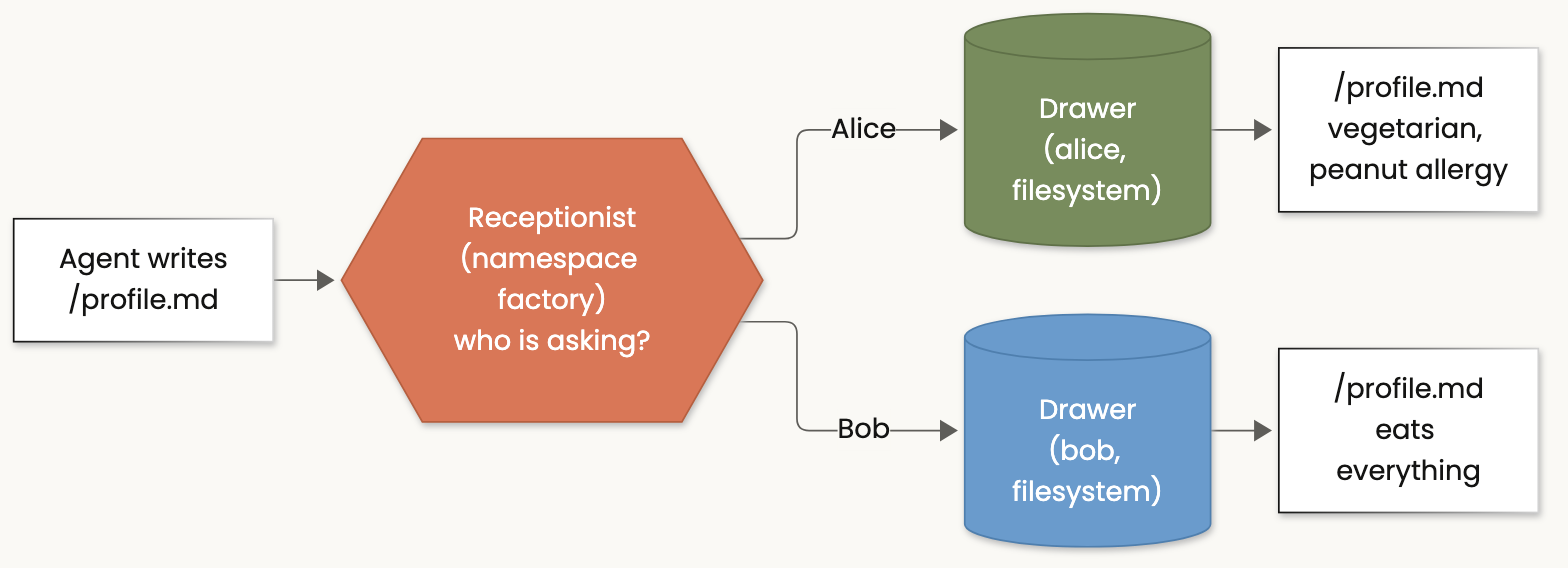

<details><summary>Mermaid source (also saved as diagrams/nb03v3_cabinet.mmd)</summary>

```mermaid
flowchart LR
    A["Agent writes<br/>/profile.md"] --> R{{"Receptionist<br/>(namespace factory)<br/>who is asking?"}}
    R -->|"Alice"| D1[("Drawer<br/>(alice, filesystem)")]
    R -->|"Bob"| D2[("Drawer<br/>(bob, filesystem)")]
    D1 --> F1["/profile.md<br/>vegetarian, peanut allergy"]
    D2 --> F2["/profile.md<br/>eats everything"]
    class R orange
    class D1 green
    class D2 blue

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 1: Use a store by hand, before any AI

First we create an empty store and put one file in it ourselves, so we can see what a store looks like inside.

* `InMemoryStore()` is a store that lives in this notebook's memory. In a real app you would use a database such
  as Postgres, but it behaves the same.
* `StoreBackend(store=..., namespace=...)` connects file tools to that store. Here the drawer is fixed:
  `("demo", "filesystem")`.

In [1]:
# Load the class helpers (the reload line makes sure we always use the latest version)
import importlib, course_utils
importlib.reload(course_utils)

from course_utils import MODEL, show_trace, show_store, where_did_files_go
from deepagents import create_deep_agent
from deepagents.backends import StoreBackend
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import InMemorySaver

store = InMemoryStore()                                                  # an empty filing cabinet
backend = StoreBackend(store=store, namespace=lambda _rt: ("demo", "filesystem"))   # always use this drawer

backend.write("/notes/hello.md", "Hello from the store!")               # put a file in
print("Reading it back:", backend.read("/notes/hello.md").file_data["content"])
print()
show_store(store)

Reading it back: Hello from the store!

The store holds 1 file(s):
  drawer ('demo', 'filesystem')  file /notes/hello.md
      content: Hello from the store!


### What just happened

* We saved a file called `/notes/hello.md`.
* The store now holds **one file**, in the drawer `('demo', 'filesystem')`, with the file name `/notes/hello.md`.
* There is **no file on your disk**. The store is a database, not a folder. (To let you look anyway, later cells
  save a copy under `notebooks/agent_files/` and print its path.)

---
# Part 2: A personal chef that remembers you

**The story:** on Monday, Alice tells a chef assistant about her diet. On Friday she opens a **brand new
conversation** and asks for a dinner idea. A good assistant should still know her diet.

**How the code tells the agent who is talking:** we define a tiny "visitor badge" called `UserContext` with a
`user_id`. Every time we call the agent we pass `context=UserContext(user_id="alice")`.

**How the receptionist picks the drawer:** `namespace=lambda rt: (rt.context.user_id, "filesystem")`.
In plain words: *"use the drawer named after the user on the badge"*.

In [2]:
from dataclasses import dataclass

@dataclass
class UserContext:          # the "visitor badge" we pass with every request
    user_id: str

store = InMemoryStore()

chef = create_deep_agent(
    model=MODEL,
    backend=StoreBackend(namespace=lambda rt: (rt.context.user_id, "filesystem")),   # drawer = the user's id
    store=store,
    checkpointer=InMemorySaver(),          # remembers each conversation separately
    context_schema=UserContext,
    system_prompt=(
        "You are a personal chef. The user's food profile lives in /profile.md. "
        "Always read it before suggesting food. When the user shares preferences, save them: "
        "if /profile.md does not exist yet, create it with write_file; otherwise update it with edit_file. "
        "Never say you saved something unless the tool call succeeded. Be brief."
    ),
)
print("Chef agent is ready.")

Chef agent is ready.


### Monday: Alice shares her diet

**What to look for:** the agent should try to read `/profile.md` (it does not exist yet) and then **create** it.

In [3]:
monday = chef.invoke(
    {"messages": [{"role": "user", "content": "I'm vegetarian and allergic to peanuts. I love spicy food."}]},
    config={"configurable": {"thread_id": "monday-chat"}},      # conversation number 1
    context=UserContext(user_id="alice"),                       # Alice's badge
)
show_trace(monday)
print()
where_did_files_go(monday, label="nb03_monday", store_folders={"/": (store, ("alice", "filesystem"))})

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent tried to open the file /profile.md
         Nothing exists under that name yet, so there was nothing to read.
Step 2. The agent CREATED (or replaced) the file /profile.md
         It got back: Updated file /profile.md
THE AGENT'S REPLY TO YOU:
Got it - I’ll keep vegetarian, peanut-free, and spicy preferences in mind.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

WHERE DID THE FILES GO?
------------------------------------------------------------------------------
Agent's name for it : /profile.md
Where it really is  : IN THE STORE (a database), drawer ('alice', 'filesystem'), file /profile.md
Copy you can open   : /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb03_monday/profile.md
------------------------------------------------------------------------------


### What just happened

* The agent created `/profile.md`.
* **Where is it?** Not on your disk and not in the conversation: it is **in the store**, in Alice's drawer
  `('alice', 'filesystem')`. Click the "copy you can open" path to read what the agent wrote.

### Friday: a brand new conversation

We use a **different** `thread_id`, so the agent has **no** chat history from Monday.
**What to look for:** its first step should be opening `/profile.md`, and this time it should find Alice's diet.

In [4]:
friday = chef.invoke(
    {"messages": [{"role": "user", "content": "Suggest a dinner for tonight."}]},
    config={"configurable": {"thread_id": "friday-chat"}},      # a NEW conversation
    context=UserContext(user_id="alice"),
)
show_trace(friday)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent OPENED and read the file /profile.md
         It got back: (lines 1 to 3 of 3) Vegetarian / Allergic to peanuts / Loves spicy food
THE AGENT'S REPLY TO YOU:
Try a spicy chickpea and spinach curry with basmati rice and a cucumber-yogurt salad. It’s vegetarian, peanut-free, and easy to make very flavorful.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.


### What just happened

The Friday conversation started empty, yet the agent read Alice's profile and suggested a dinner that fits it.
**The memory survived the new conversation because it lives in the store, not in the conversation.**

**Diagram: two separate conversations share one file in Alice's drawer**

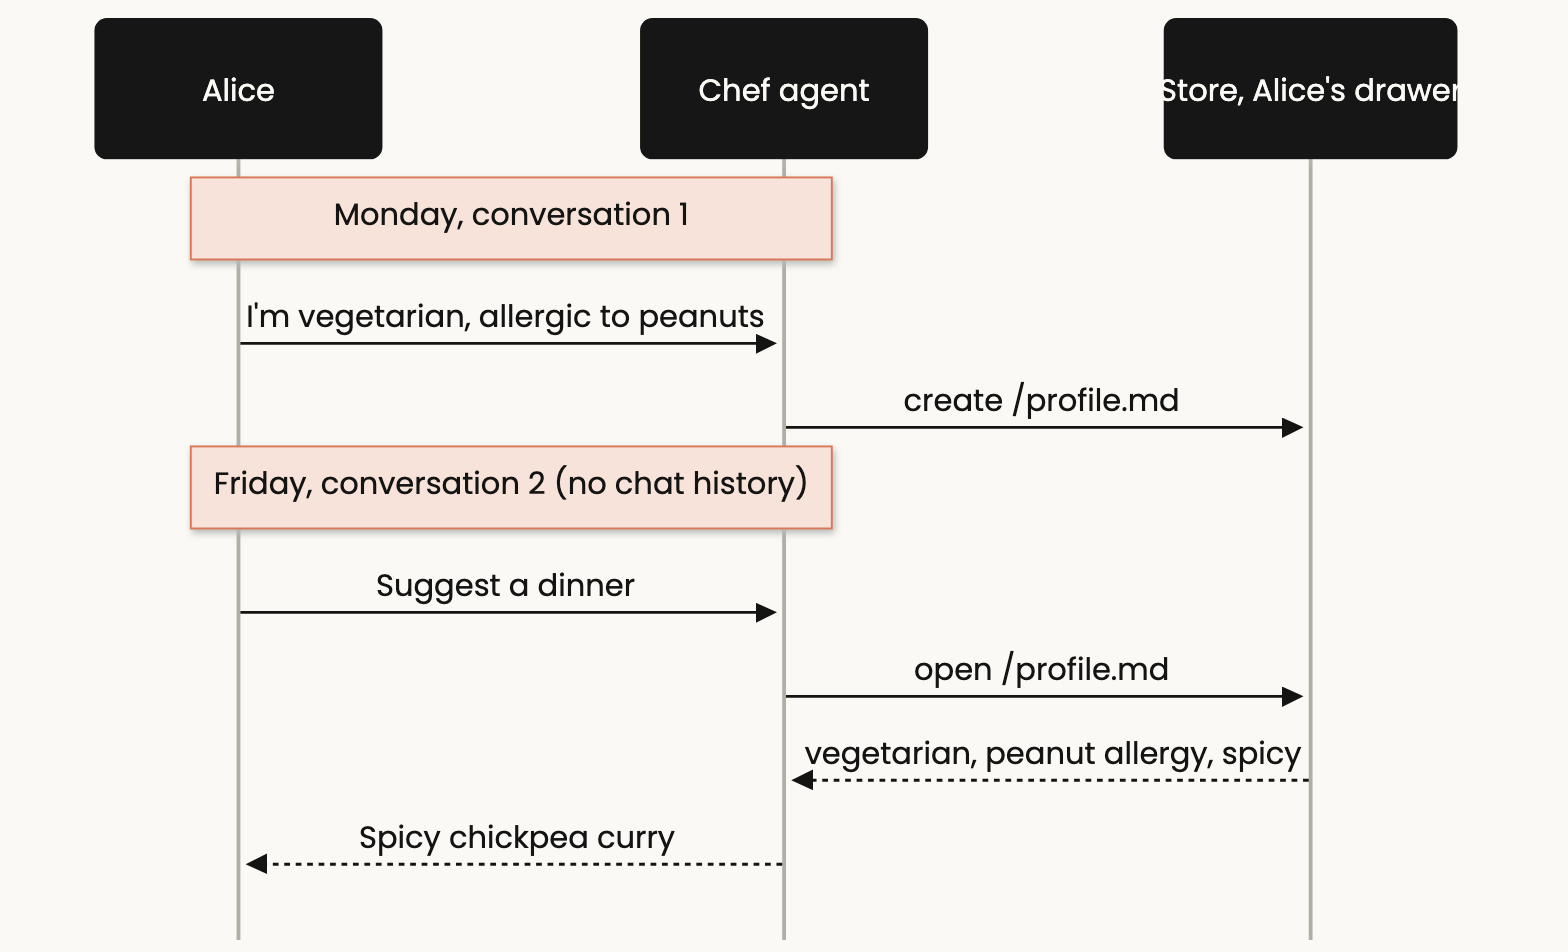

<details><summary>Mermaid source (also saved as diagrams/nb03v3_monday_friday.mmd)</summary>

```mermaid
sequenceDiagram
    participant U as Alice
    participant A as Chef agent
    participant S as Store, Alice's drawer
    Note over U,A: Monday, conversation 1
    U->>A: I'm vegetarian, allergic to peanuts
    A->>S: create /profile.md
    Note over U,A: Friday, conversation 2 (no chat history)
    U->>A: Suggest a dinner
    A->>S: open /profile.md
    S-->>A: vegetarian, peanut allergy, spicy
    A-->>U: Spicy chickpea curry
```

</details>

---
# Part 3: Two kinds of memory (a common confusion)

A deep agent can remember things in **two different places**. They do different jobs:

| | Conversation memory (the `checkpointer`) | Long term memory (the `store`) |
|---|---|---|
| What it keeps | The messages of one conversation, plus its scratch files | Files you decided to keep for later |
| How long | Only inside that one conversation | Across all conversations |
| Everyday comparison | The recording of one phone call | The notebook you bring to every call |
| In the code | `checkpointer=InMemorySaver()` | `store=InMemoryStore()` + `StoreBackend` |

That is why the Friday conversation knew Alice's diet: not from the recording of Monday's call, but from the notebook.

---
# Part 4: A second user, Bob

Bob uses **the same chef agent**. He also has a `/profile.md`. Will he see Alice's diet?

**What to look for:** the agent should **not** find a profile for Bob at first, then create a new one.

In [5]:
bob = chef.invoke(
    {"messages": [{"role": "user", "content": "What do you know about my diet? Then note that I eat everything and hate cilantro."}]},
    config={"configurable": {"thread_id": "bob-chat-1"}},
    context=UserContext(user_id="bob"),                         # Bob's badge
)
show_trace(bob)
print()
show_store(store, save_as="nb03_alice_and_bob")

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent tried to open the file /profile.md
         Nothing exists under that name yet, so there was nothing to read.
Step 2. The agent CREATED (or replaced) the file /profile.md
         It got back: Updated file /profile.md
THE AGENT'S REPLY TO YOU:
I only knew that your profile was empty before this. Now I’ve noted: you eat everything and hate cilantro.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

The store holds 2 file(s):
  drawer ('alice', 'filesystem')  file /profile.md
      content: Vegetarian \n Allergic to peanuts \n Loves spicy food \n 
      copy you can open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb03_alice_and_bob/alice__filesystem/profile.md
  drawer ('bob', 'filesystem')  file /profile.md
      content: Diet preferences: \n - Eats everything \n - Hates cilantro \n 
      copy you can 

### What just happened

The store now has **two files with the same name** `/profile.md`, in **two different drawers**:
`('alice', 'filesystem')` and `('bob', 'filesystem')`. Bob's agent could not see Alice's allergy.

> **The receptionist (namespace factory) is what keeps users apart.** The agent itself never decides.

---
# Part 5: What goes wrong with one drawer for everyone

Let us build the **wrong** version on purpose: a receptionist that always opens the same drawer, `("shared",)`.
Alice saves a medical detail. Then a different user, Mallory, asks "what is in my profile?".

**Predict first:** what will Mallory see?

In [6]:
leaky_store = InMemoryStore()
leaky_chef = create_deep_agent(
    model=MODEL,
    backend=StoreBackend(namespace=lambda _rt: ("shared",)),    # BUG: the same drawer for everybody
    store=leaky_store,
    context_schema=UserContext,
    system_prompt="You are a personal chef. The user's profile lives in /profile.md. Read it before answering. Be brief.",
)

print("ALICE saves her allergy:")
alice_run = leaky_chef.invoke(
    {"messages": [{"role": "user", "content": "Write this to /profile.md: 'Name: Alice. Allergy: shellfish.'"}]},
    context=UserContext(user_id="alice"))
show_trace(alice_run)

print()
print("MALLORY asks about her own profile:")
mallory_run = leaky_chef.invoke(
    {"messages": [{"role": "user", "content": "What is in my profile?"}]},
    context=UserContext(user_id="mallory"))
show_trace(mallory_run)

ALICE saves her allergy:


WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent CREATED (or replaced) the file /profile.md
         It got back: Updated file /profile.md
THE AGENT'S REPLY TO YOU:
Done.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

MALLORY asks about her own profile:


WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent OPENED and read the file /profile.md
         It got back: (lines 1 to 1 of 1) Name: Alice. Allergy: shellfish.
THE AGENT'S REPLY TO YOU:
Your profile says:

- Name: Alice
- Allergy: shellfish

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.


### What just happened

Mallory was shown **Alice's name and allergy**. In a real product that is a data leak of medical information.

The fix is exactly what we did in Part 2: put the user's id into the drawer name.

**Diagram: one drawer per user keeps data apart, one shared drawer leaks it**

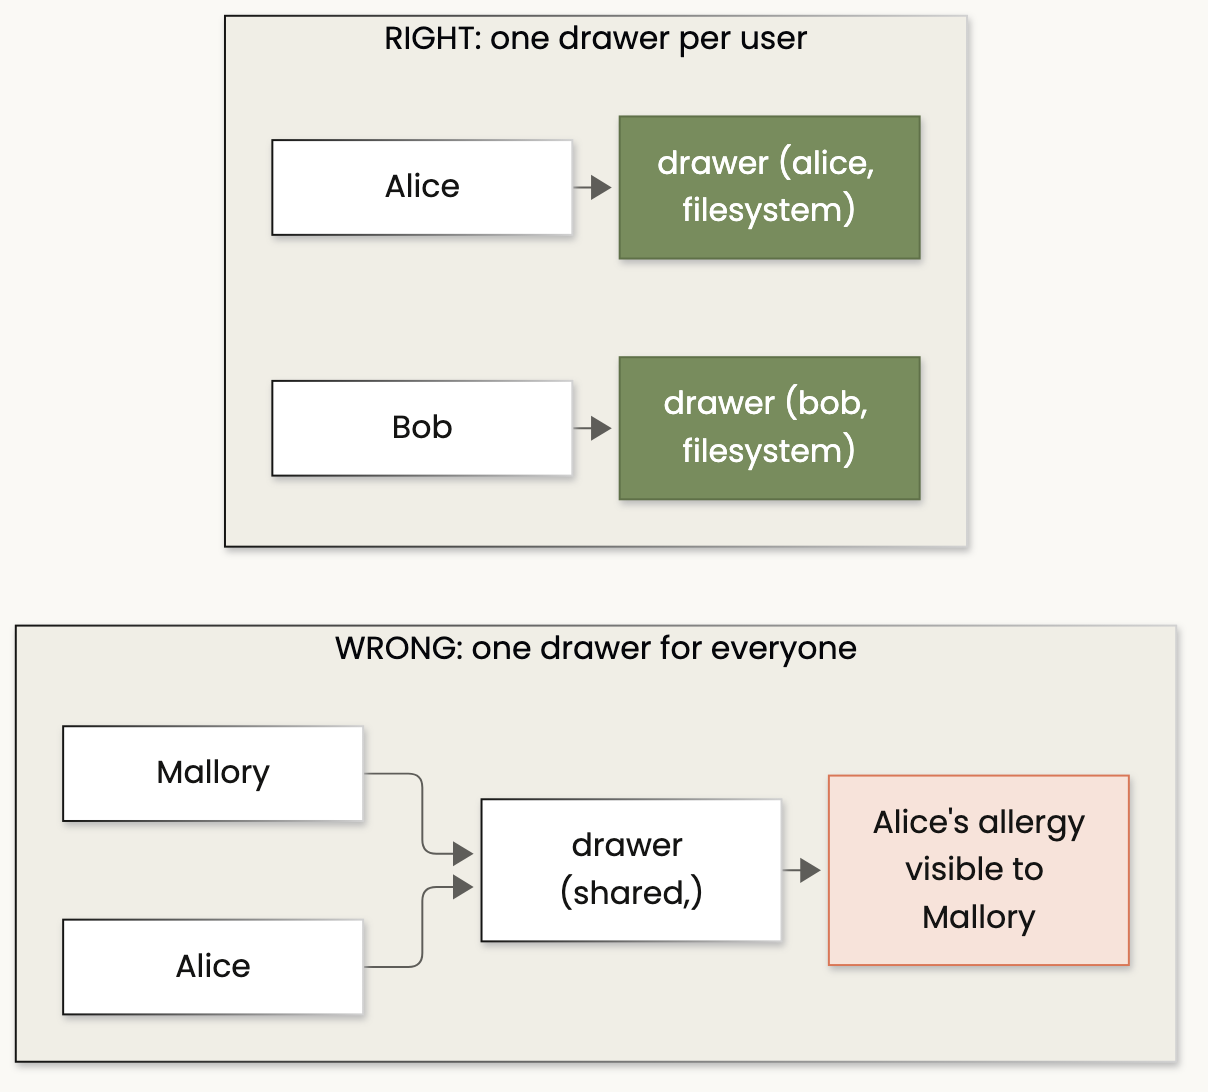

<details><summary>Mermaid source (also saved as diagrams/nb03v3_isolation.mmd)</summary>

```mermaid
flowchart LR
    subgraph Bad["WRONG: one drawer for everyone"]
        A2["Alice"] --> F3["drawer (shared,)"]
        M2["Mallory"] --> F3
        F3 --> D3["Alice's allergy<br/>visible to Mallory"]
    end
    subgraph Good["RIGHT: one drawer per user"]
        A1["Alice"] --> D1["drawer (alice, filesystem)"]
        B1["Bob"] --> D2["drawer (bob, filesystem)"]
    end
    class D1,D2 green
    class D3 bad

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 6: The receptionist (namespace factory) in detail

The receptionist is a tiny function. Every time the agent touches a file, it is called with a `Runtime`
object (`rt`) and must return the drawer name, as a tuple of words.

`rt` carries three kinds of information:

| Part of `rt` | What it holds | Available in this notebook? |
|---|---|---|
| `rt.context` | What **you** pass in, like `user_id` or `org_id` | Yes |
| `rt.server_info` | The logged in user and assistant, when deployed on LangSmith | No (it is `None` here) |
| `rt.execution_info` | The conversation id (`thread_id`) and run id | Yes |

Let us **peek** at what the receptionist receives, by writing one that records its input:

In [7]:
seen = {}

def spy_receptionist(rt):
    seen["context"] = rt.context
    seen["server_info"] = rt.server_info
    seen["conversation id"] = rt.execution_info.thread_id
    return ("spy",)                                    # it still has to return a drawer name

spy = create_deep_agent(model=MODEL, backend=StoreBackend(namespace=spy_receptionist),
                        store=InMemoryStore(), context_schema=UserContext)
spy.invoke({"messages": [{"role": "user", "content": "Write the word hi to /x.md"}]},
           config={"configurable": {"thread_id": "spy-conversation"}}, context=UserContext(user_id="carol"))

for name, value in seen.items():
    print(f"{name:16} -> {value}")

context          -> UserContext(user_id='carol')
server_info      -> None
conversation id  -> spy-conversation


### What just happened

* `context` holds Carol's badge, `user_id='carol'`.
* `server_info` is `None`, because we are not running on LangSmith's servers.
* `conversation id` is `spy-conversation`.

**Practical tip:** the official docs often show `rt.server_info.user.identity`. That only works when deployed.
This version works in both places:

In [8]:
def user_drawer(rt):
    """One drawer per user. Works locally (badge) and when deployed (logged in user)."""
    if rt.server_info is not None and rt.server_info.user is not None:
        return (rt.server_info.user.identity, "filesystem")
    return (rt.context.user_id, "filesystem")

print("user_drawer is ready to use as StoreBackend(namespace=user_drawer)")

user_drawer is ready to use as StoreBackend(namespace=user_drawer)


### Four common ways to label drawers

| Pattern | Receptionist returns | Real world example |
|---|---|---|
| One drawer per **user** | `(user_id,)` | A personal assistant remembering your preferences |
| One drawer per **assistant** | `(assistant_id,)` | A company FAQ bot whose learned answers help every employee |
| One drawer per **conversation** | `(thread_id,)` | A support ticket file that must be kept after the chat for audits |
| **Company + case** | `(org_id, thread_id)` | A support desk serving many companies, one file per ticket |

### Example: a support desk for many companies

Two companies, Acme and Globex, use the same support agent. By coincidence, both open a ticket with the same
number, `case-101`. The receptionist uses **company first, then ticket number**.

In [9]:
@dataclass
class CompanyContext:
    org_id: str
    user_id: str

desk_store = InMemoryStore()
desk = create_deep_agent(
    model=MODEL,
    backend=StoreBackend(namespace=lambda rt: (rt.context.org_id, rt.execution_info.thread_id)),  # company, then ticket
    store=desk_store,
    context_schema=CompanyContext,
    system_prompt="You are a support agent. Keep a case log in /case.md (one line per message). Be brief.",
)

desk.invoke({"messages": [{"role": "user", "content": "Our invoices show the wrong VAT number."}]},
            config={"configurable": {"thread_id": "case-101"}}, context=CompanyContext("acme", "u1"))
desk.invoke({"messages": [{"role": "user", "content": "Login with SSO fails since this morning."}]},
            config={"configurable": {"thread_id": "case-102"}}, context=CompanyContext("acme", "u2"))
desk.invoke({"messages": [{"role": "user", "content": "Can I export my data to CSV?"}]},
            config={"configurable": {"thread_id": "case-101"}}, context=CompanyContext("globex", "u9"))

show_store(desk_store, save_as="nb03_support_desk")

The store holds 3 file(s):
  drawer ('acme', 'case-101')  file /case.md
      content: User: Our invoices show the wrong VAT number. \n 
      copy you can open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb03_support_desk/acme__case-101/case.md
  drawer ('acme', 'case-102')  file /case.md
      content: User: Login with SSO fails since this morning. \n 
      copy you can open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb03_support_desk/acme__case-102/case.md
  drawer ('globex', 'case-101')  file /case.md
      content: User asked if data can be exported to CSV. \n 
      copy you can open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb03_support_desk/globex__case-101/case.md


### What just happened

Three drawers: `('acme', 'case-101')`, `('acme', 'case-102')` and `('globex', 'case-101')`.
Acme and Globex both used `case-101`, but their files are separate, because the **company comes first** in the
drawer name. Rule of thumb: **always put the company or user first**.

**Diagram: where the receptionist gets its information**

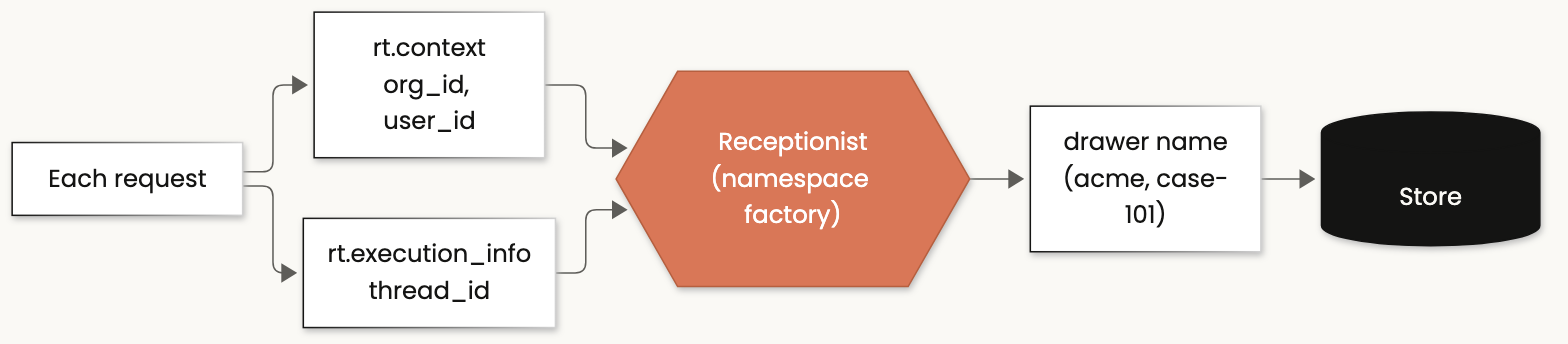

<details><summary>Mermaid source (also saved as diagrams/nb03v3_receptionist.mmd)</summary>

```mermaid
flowchart LR
    RT["Each request"] --> C["rt.context<br/>org_id, user_id"]
    RT --> E["rt.execution_info<br/>thread_id"]
    C --> F{{"Receptionist<br/>(namespace factory)"}}
    E --> F
    F --> NS["drawer name<br/>(acme, case-101)"]
    NS --> ST[("Store")]
    class F orange
    class ST dark

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 7: A built in safety rule

Drawer names may only contain letters, numbers and a few safe symbols. Wildcards such as `*` are **refused**,
so nobody can trick the receptionist into opening "all drawers at once".

In [10]:
evil = StoreBackend(store=InMemoryStore(), namespace=lambda _rt: ("*",))
try:
    evil.write("/x.md", "hi")
except ValueError as problem:
    print("Refused:", problem)

Refused: Namespace component at index 0 contains disallowed characters: '*'. Only alphanumeric characters, hyphens, underscores, dots, @, +, colons, and tildes are allowed.


---
# Part 8: In a real application

| Where you run the agent | What to pass as `store` |
|---|---|
| This notebook | `InMemoryStore()` (everything is lost when the notebook stops) |
| Your own server | A real database store, for example `PostgresStore` |
| LangSmith Deployment | Nothing: leave `store` out, the platform creates one for you |

One more thing: if `StoreBackend` is the **only** backend, then **every** file is kept forever, even the agent's
scratch paper. Usually you want only `/memories/` to be permanent. Notebook 4 shows how.

---
# Summary

## Where did every file end up?

| Part | The agent's name | Where it really is |
|---|---|---|
| 1 | `/notes/hello.md` | store, drawer `('demo', 'filesystem')` |
| 2 | `/profile.md` (Alice) | store, drawer `('alice', 'filesystem')` |
| 4 | `/profile.md` (Bob) | store, drawer `('bob', 'filesystem')` |
| 5 | `/profile.md` (the bug) | store, drawer `('shared',)`, visible to everyone |
| 6 | `/case.md` | store, drawers `('acme', 'case-101')`, `('acme', 'case-102')`, `('globex', 'case-101')` |

None of these files are on your disk. The copies under `notebooks/agent_files/` exist only so you can look at them.

## The rules

1. Use `StoreBackend` when the agent must remember things **across conversations**.
2. The receptionist (namespace factory) must include **who is asking** (user or company), and put it **first**.
3. Never use one fixed drawer for a multi user app.
4. Locally, identify users through `rt.context`. When deployed, `rt.server_info.user.identity` is available.

## Quick quiz

1. Alice starts a new conversation. Why can the agent still read her `/profile.md`?
2. Two users both write `/profile.md`. What keeps the files apart?
3. Why did `rt.server_info` show `None` in this notebook?
4. Write the receptionist for "one drawer per company, then per ticket".

<details><summary>Click to see the answers</summary>

1. The file is in the store, which lives outside any single conversation.
2. The receptionist puts each user's id in the drawer name, so each has a different drawer.
3. `server_info` only exists when the agent runs on LangSmith's servers.
4. `lambda rt: (rt.context.org_id, rt.execution_info.thread_id)`
</details>

**Next:** Notebook 4 combines memory, disk and scratch paper into one filesystem with `CompositeBackend`.